# Evaluation: New Method vs AnthroScore

As [AnthroSet (Lonke et al., 2025)](https://github.com/doriellel/anthroset/), was essentially used to calibrate a method rather than to evaluate one, [Anthropomorphism Corpus (Shardlow et al., 2025)](https://github.com/mattshardlow/Anthropomorphism_Corpus/) provides a new chance to show that the new method is indeed an improvement on AnthroScore.

Some earlier inspection of Shardlow's corpus has shown that the MLM-based method doesn't work out of the box, one reason being that there isn't a readily available entity which human-likeness could be evaluated, unlike in AnthroSet. As the two methods under inspection utilize a masked language model, the sentences need to be masked in a reasonable way. It is further noted by earlier tests that AnthroScore performs better with noun chunk masking strategy, while the new method should be using minimal masking strategy. Thus, two versions of a sentence should be created.

This is done by utilizing dependy parsing, POS tagging, and entity recognition via a spaCy model.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report
from collections import Counter, defaultdict

In [ ]:
import spacy
nlp = spacy.load("en_core_web_sm")

## Load the corpus

The corpus has been cleaned from LaTeX artifacts by me earlier (using the same pipeline component than in the file `preprocessing/preprocess.py`), so it does not fully correspond to the original corpus. Additionally, it was noted that the corpus contained empty texts (containing line break characters only) that had diverging annotations, raising some questions about the quality of the corpus. However, as there are not other options readily available, it was utilized nevertheless.

In [ ]:
df = pd.read_csv("corpus_shardlow_cleaned.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   category        4340 non-null   object
 1   source          4340 non-null   object
 2   label_str       4340 non-null   object
 3   text            4340 non-null   object
 4   id              4340 non-null   int64 
 5   subset          4340 non-null   object
 6   label           4340 non-null   int64 
 7   label_binary    4340 non-null   int64 
 8   category_short  4340 non-null   object
 9   text_mod        4330 non-null   object
dtypes: int64(3), object(7)
memory usage: 339.2+ KB


In [ ]:
# Drop the empty sentences
df = df.dropna()

In [ ]:
test = df[df["subset"] == "test"].copy()
test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 883 entries, 0 to 4283
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   category        883 non-null    object
 1   source          883 non-null    object
 2   label_str       883 non-null    object
 3   text            883 non-null    object
 4   id              883 non-null    int64 
 5   subset          883 non-null    object
 6   label           883 non-null    int64 
 7   label_binary    883 non-null    int64 
 8   category_short  883 non-null    object
 9   text_mod        883 non-null    object
dtypes: int64(3), object(7)
memory usage: 75.9+ KB


In [ ]:
test.category_short.value_counts(normalize=True)

,proportion
category_short,
acl,0.791619
news,0.208381


In [ ]:
test.label_str.value_counts(normalize=True)

,proportion
label_str,
Non-Anthropomorphic Claim,0.749717
Ambiguous Anthropomorphic Claim,0.204983
Explicit Anthropomorphic Claim,0.045300


## Mask the sentences using the entity list

(Upload the file `all_entities.txt`)

In [ ]:
import re
with open("all_entities.txt") as file:
  ents = set((line.strip() for line in file if line.strip()))

target_regex = re.compile(
    r"\b(" + "|".join(re.escape(entity) for entity in ents) + r")\b", flags=re.IGNORECASE
)

In [ ]:
sents = list(nlp.pipe(test.text_mod.tolist()))

In [ ]:
masked_sents = []
for i, sent in enumerate(sents):
  for nc in sent.noun_chunks:
    found = list(target_regex.finditer(nc.text.lower()))
    if found:
      for j, m in enumerate(found):
        masked = sent.text[:nc.start_char] + "<mask>" + sent.text[nc.end_char:]
        masked_minimal = sent.text[:nc.start_char+m.start()] + "[MASK]" + sent.text[nc.start_char+m.end():]
        masked_sents.append((i, j, sent.text, masked, masked_minimal, nc.text, m[0]))

In [ ]:
columns = ["orig_idx", "match_idx", "sentence", "masked_sentence", "masked_sentence_minimal", "noun_chunk", "str_match"]

In [ ]:
masks = pd.DataFrame(masked_sents, columns=columns)

In [ ]:
masks.orig_idx.nunique() / len(test)

0.7281993204983013

(Could also have uploaded separate entity files instead of manually re-labeling each entity)

In [ ]:
char_to_cat = {"h": "human", "a": "artifact", "l": "lm"}
ent_to_cat = {}
for ent in ents:
  print(ent)
  cat = input("Assign category (h/a/l):")
  ent_to_cat[ent] = char_to_cat[cat]

ai
Assign category (h/a/l):a
approaches
Assign category (h/a/l):a
lms
Assign category (h/a/l):l
llms
Assign category (h/a/l):l
models
Assign category (h/a/l):a
companies
Assign category (h/a/l):h
he
Assign category (h/a/l):h
llama
Assign category (h/a/l):l
agent
Assign category (h/a/l):a
foundation models
Assign category (h/a/l):l
algorithm
Assign category (h/a/l):a
large language models
Assign category (h/a/l):l
large language model
Assign category (h/a/l):l
gpt
Assign category (h/a/l):l
him
Assign category (h/a/l):h
author
Assign category (h/a/l):h
gemini
Assign category (h/a/l):l
systems
Assign category (h/a/l):a
she
Assign category (h/a/l):h
i
Assign category (h/a/l):h
language model
Assign category (h/a/l):l
architecture
Assign category (h/a/l):a
palm
Assign category (h/a/l):l
her
Assign category (h/a/l):h
claude
Assign category (h/a/l):l
software
Assign category (h/a/l):a
teachers
Assign category (h/a/l):h
applications
Assign category (h/a/l):a
organizations
Assign category (h/a/

In [ ]:
ent_to_cat

{'ai': 'artifact',
 'approaches': 'artifact',
 'lms': 'lm',
 'llms': 'lm',
 'models': 'artifact',
 'companies': 'human',
 'he': 'human',
 'llama': 'lm',
 'agent': 'artifact',
 'foundation models': 'lm',
 'algorithm': 'artifact',
 'large language models': 'lm',
 'large language model': 'lm',
 'gpt': 'lm',
 'him': 'human',
 'author': 'human',
 'gemini': 'lm',
 'systems': 'artifact',
 'she': 'human',
 'i': 'human',
 'language model': 'lm',
 'architecture': 'artifact',
 'palm': 'lm',
 'her': 'human',
 'claude': 'lm',
 'software': 'artifact',
 'teachers': 'human',
 'applications': 'artifact',
 'organizations': 'human',
 'technology': 'artifact',
 'genai': 'artifact',
 'humans': 'human',
 'language models': 'lm',
 'we': 'human',
 'transformers': 'lm',
 'framework': 'artifact',
 'transformer': 'lm',
 'users': 'human',
 'network': 'artifact',
 'people': 'human',
 'model': 'artifact',
 'artificial intelligence': 'artifact',
 'agents': 'artifact',
 'pre-trained language model': 'lm',
 'pre-train

In [ ]:
human_ents = set((ent for ent, cat in ent_to_cat.items() if cat == "human"))
artifact_ents = set((ent for ent, cat in ent_to_cat.items() if cat == "artifact"))
lm_ents = set((ent for ent, cat in ent_to_cat.items() if cat == "lm"))

In [ ]:
def assign_category(x):
  if x in human_ents:
    return "human"
  elif x in artifact_ents:
    return "artifact"
  elif x in lm_ents:
    return "lm"
  else:
    raise ValueError(f"{x} is not a known category")

In [ ]:
masks["str_match_lower"] = masks["str_match"].str.lower()
masks["ent_type"] = masks["str_match_lower"].apply(assign_category)

In [ ]:
masks[masks["ent_type"] != "human"].orig_idx.nunique() / len(test)

0.522083805209513

Using just a regular expression with the chosen set of entities was able to cover about 52% of the sentences in the test set. Not optimal, but will do.

In [ ]:
masks

,orig_idx,match_idx,sentence,masked_sentence,masked_sentence_minimal,noun_chunk,str_match,str_match_lower,ent_type
0,0,0,Tens of thousands of tech workers recently lai...,Tens of thousands of tech workers recently lai...,Tens of thousands of tech workers recently lai...,big tech companies,companies,companies,human
1,1,0,“The AI boom has brought the energy back into ...,“<mask> has brought the energy back into the B...,“The [MASK] boom has brought the energy back i...,The AI boom,ai,ai,artifact
2,2,0,The AI boom is also luring back founders of ot...,<mask> is also luring back founders of other k...,The [MASK] boom is also luring back founders o...,The AI boom,ai,ai,artifact
3,2,0,The AI boom is also luring back founders of ot...,The AI boom is also luring back founders of ot...,The AI boom is also luring back founders of ot...,tech companies,companies,companies,human
4,3,0,Investors have already announced $10.7 billion...,Investors have already announced $10.7 billion...,Investors have already announced $10.7 billion...,generative AI start-ups,ai,ai,artifact
...,...,...,...,...,...,...,...,...,...
1115,881,0,It can do that because of the incredible compu...,"It can do that because of <mask>, which has ca...",It can do that because of the incredible compu...,the incredible computational power AI systems ...,ai,ai,artifact
1116,881,1,It can do that because of the incredible compu...,"It can do that because of <mask>, which has ca...",It can do that because of the incredible compu...,the incredible computational power AI systems ...,systems,systems,artifact
1117,882,0,The government says the UK will host a global ...,The government says the UK will host <mask> th...,The government says the UK will host a global ...,a global AI summit,ai,ai,artifact
1118,882,0,The government says the UK will host a global ...,The government says the UK will host a global ...,The government says the UK will host a global ...,he,he,he,human


In [ ]:
masks.to_csv("masks.csv", index=False)

In [ ]:
masks.ent_type.value_counts()

,count
ent_type,
artifact,530
human,434
lm,156


In [ ]:
masks.str_match_lower.value_counts()

,count
str_match_lower,
we,288
models,120
model,112
ai,107
systems,35
i,32
approach,28
language models,25
system,22


## Calculate AnthroScores

This is a slightly modified variant of the original implementation, and additionally the performance using `Ġ`-prefixed tokens is compared to the non-prefixed tokens.

In [ ]:
import numpy as np
import torch
from tqdm import tqdm
from transformers import RobertaTokenizer, RobertaForMaskedLM
import scipy

TERMS = ['he', 'she', 'her', 'him', 'He', 'She', 'Her', 'it', 'its', 'It', 'Its']
TERMS_BPE = ['Ġhe', 'Ġshe', 'Ġher', 'Ġhim', 'ĠHe', 'ĠShe', 'ĠHer', 'Ġit', 'Ġits', 'ĠIt', 'ĠIts']
FIRST_NONHUM_INDEX = TERMS.index("it")

def get_term_ids(terms):
  return torch.tensor([tokenizer.convert_tokens_to_ids(w) for w in terms])

model = RobertaForMaskedLM.from_pretrained('roberta-base')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
print("BERT model loaded on %s"%device)
tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

def get_prediction(sent, terms = TERMS):
    target_inds = [tokenizer.get_vocab()[x] for x in terms]
    token_ids = tokenizer.encode(sent,return_tensors='pt').to(device)
    masked_position = (token_ids.squeeze() == tokenizer.mask_token_id).nonzero()
    try:
        masked_pos = [mask.item() for mask in masked_position][0]
    except IndexError:
        temp = tokenizer.encode(sent, return_tensors='pt').to(device)
        masked_position = (temp.squeeze() == tokenizer.mask_token_id).nonzero()
        try:
            if (int(masked_position[0] + 256)) > len(temp[0]):
                token_ids = torch.reshape(temp[0][-512:], (1, 512))
            else:
                token_ids = torch.reshape(temp[0][masked_position[0] - 256:masked_position[0]+256], (1, 512))
        except IndexError:
            return np.empty((len(terms),))
        masked_position = (token_ids.squeeze() == tokenizer.mask_token_id).nonzero()
        masked_pos = [mask.item() for mask in masked_position ][0]

    with torch.no_grad():
        output = model(token_ids)

    last_hidden_state = output[0].squeeze()
    mask_hidden_state = last_hidden_state[masked_pos].cpu().numpy()

    probs = scipy.special.softmax(mask_hidden_state)
    scores = np.array([probs[i] for i in target_inds])
    return scores

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

BERT model loaded on cuda


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [ ]:
def main(sentences):

  def get_scores(terms):
    target_inds = [tokenizer.get_vocab()[x] for x in terms]
    print("Target inds:", target_inds)
    results = []
    for sent in tqdm(sentences):
      scores = get_prediction(sent, terms)
      human_scores = np.sum(scores[:FIRST_NONHUM_INDEX])
      nonhuman_scores = np.sum(scores[FIRST_NONHUM_INDEX:])
      final_scores = np.log(human_scores) - np.log(nonhuman_scores)
      results.append(final_scores)
    return results

  print("Calculating original AnthroScores")
  orig_results = get_scores(TERMS)

  print("\nCalculating BPE-corrected scores")
  modified_results = get_scores(TERMS_BPE)
  return orig_results, modified_results

In [ ]:
masks = pd.read_csv("masks.csv")
masks.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1120 entries, 0 to 1119
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   orig_idx                 1120 non-null   int64 
 1   match_idx                1120 non-null   int64 
 2   sentence                 1120 non-null   object
 3   masked_sentence          1120 non-null   object
 4   masked_sentence_minimal  1120 non-null   object
 5   noun_chunk               1120 non-null   object
 6   str_match                1120 non-null   object
 7   str_match_lower          1120 non-null   object
 8   ent_type                 1120 non-null   object
dtypes: int64(2), object(7)
memory usage: 78.9+ KB


In [ ]:
original, bpe = main(masks["masked_sentence"].tolist())

Calculating original AnthroScores
Target inds: [700, 8877, 1843, 24770, 894, 2515, 13584, 405, 2629, 243, 30872]


100%|██████████| 1120/1120 [08:50<00:00,  2.11it/s]



Calculating BPE-corrected scores
Target inds: [37, 79, 69, 123, 91, 264, 1405, 24, 63, 85, 3139]


100%|██████████| 1120/1120 [07:35<00:00,  2.46it/s]


In [ ]:
masks["anthroscore"] = original
masks["anthroscore_bpe"] = bpe
masks.to_csv("masks.csv", index=False)

## Calculate scores with the new method

### Method

In [ ]:
# ── 0. Imports ─────────────────────────────────────────────────────────────────

import torch
import torch.nn.functional as F
import numpy as np
from dataclasses import dataclass, field
from transformers import pipeline, Pipeline, AutoTokenizer, AutoModel, PreTrainedModel, PreTrainedTokenizer
from typing import Iterable, overload, Literal
from collections import OrderedDict
from pathlib import Path
import re
import csv
import gc

import logging

logger = logging.getLogger(__name__)
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s %(name)s (line %(lineno)d) | %(levelname)s: %(message)s"
    )

# ── 1. Constants ────────────────────────────────────────────────────────────────

_prototype_cache = {}

ANIMATE_DESCRIPTIONS = [
    "a living person, human being, or individual who can act and think",
    "a human who makes decisions and has intentions",
    "someone who thinks, feels, and can take action",
    "a name of a person or a personal pronoun referring to a human",
    "a person with a professional role such as a doctor, scientist, or engineer",
    "a human subject or participant in a study or experiment",
    "an individual who experiences emotions and has subjective awareness",
    "a named historical or contemporary figure such as an author or inventor",
    "a collective group of humans such as a team, committee, or community",
    "a pronoun referring to one or more people such as I, you, he, she, or we",
    "a human agent who performs actions and bears responsibility",
    "a living creature capable of perception and voluntary movement",
    "an animate being with a social role or identity",
    "a person referred to by their job title, role, or name"
]

INANIMATE_DESCRIPTIONS = [
    "a non-living machine, device, tool, or system",
    "a piece of software or automated system without consciousness",
    "an object or artifact that cannot think or feel",
    "a technical system or piece of equipment",
    "an abstract concept or a thing that does not have a physical form",
    "a physical object with no capacity for thought or intention",
    "an automated process or algorithm that executes without awareness",
    "a product, platform, or application built by humans",
    "a natural or man-made structure such as a building or infrastructure",
    "a measurement, metric, or quantitative value",
    "a document, report, or piece of written output",
    "an institution or organization treated as a non-human entity",
    "a chemical substance, material, or physical phenomenon",
    "a vehicle, vessel, or means of transport",
    "something that is acted upon rather than acting of its own will",
    "a pronoun referring to an inanimate object such as it"
]

CLASS_DESCRIPTIONS = [ANIMATE_DESCRIPTIONS, INANIMATE_DESCRIPTIONS]
CLASS_NAMES_DEFAULT = ["animate", "inanimate"]

# Cache the static embeddings in format {(model_id, prefix, template, token): np.ndarray}
_static_emb_cache: dict[tuple[str, str, str, str], np.ndarray] = {}

MAX_CACHED_MODELS = 5
# Cache the models to avoid redownloads
_model_cache = OrderedDict()

MLM_ID = "distilbert/distilbert-base-uncased"
EMB_ID = "sentence-transformers/all-MiniLM-L6-v2"


# ── 2. Model registry ───────────────────────────────────────────────────────────
# Pooling strategy and any required input prefix, sourced from official model cards.
# Add new embedding models here — no other code changes needed.

EMB_MODEL_CONFIGS = {
    # mean pool — no prefix
    "sentence-transformers/all-MiniLM-L6-v2":  {"pooling": "mean", "query_prefix": "", "doc_prefix": "", "static_template": "What is the definition of [PLACEHOLDER]?"},
    # mean pool - prefix
    "nomic-ai/modernbert-embed-base":          {"pooling": "mean", "query_prefix": "search_query: ", "doc_prefix": "search_document: ", "static_template": "What is the most accurate description of [PLACEHOLDER]?"},
    # CLS pool — no prefix
    "BAAI/bge-base-en-v1.5":                   {"pooling": "cls",  "query_prefix": "", "doc_prefix": "", "static_template": "Can you define [PLACEHOLDER]?"},
    # last token pool - prefix
    "jinaai/jina-embeddings-v5-text-nano":     {"pooling": "last", "query_prefix": "Query: ", "doc_prefix": "Document: ", "static_template": "Can you define [PLACEHOLDER]?"},
}

def get_emb_config(model_id: str) -> dict:
    if model_id in EMB_MODEL_CONFIGS:
        return EMB_MODEL_CONFIGS[model_id]
    # Fallback: warn and use mean pooling with no prefix nor template
    logger.warning(f"""  ⚠ '{model_id}' not in registry — defaulting to mean pooling, no prefix, no template.
                       Check the model card and add it to EMB_MODEL_CONFIGS if needed.""")
    return {"pooling": "mean", "query_prefix": "", "doc_prefix": "", "static_template": ""}


# ── 3. Config dataclass ──────────────────────────────────────────────────────

@dataclass
class Config:
    # MLM
    mlm_pipe:             Pipeline  # HF fill-mask pipeline — handles all model quirks
    mlm_model_id:         str

    # Embedding model
    emb_tokenizer:        PreTrainedTokenizer
    emb_model:            PreTrainedModel
    emb_model_id:         str
    emb_config:           dict  # {"pooling": "mean"|"cls"|"last", "query_prefix": str, "doc_prefix": str, "static_template": str}

    # Prototype setup
    class_descriptions:   list[list[str]]
    class_names:          list[str]
    class_protos:         np.ndarray = field(init=False, default_factory=lambda: np.empty(0)) # (n_classes, hidden_dim)

    mask_token:           str = field(init=False, default="") # [MASK] for BERTs, <mask> for RoBERTa
    template_placeholder: str = "[PLACEHOLDER]"

    def build_prototype_vectors(self):
        """
        Embed each class description list, average per class, re-normalize.
        Returns (class_protos, class_names).
        """

        if not self.emb_model_id in _prototype_cache:

            logger.info("Building prototype vectors…")
            protos = []
            for descriptions in self.class_descriptions:
                embs  = embed_texts_batch(descriptions, self, "doc_prefix") # (n_desc, hidden_dim)
                proto = embs.mean(axis=0)
                proto = proto / (np.linalg.norm(proto) + 1e-12) # re-normalize back to unit length
                protos.append(proto)

            _prototype_cache[self.emb_model_id] = np.array(protos)
            logger.info("Prototype vectors cached.")

        return _prototype_cache[self.emb_model_id] # (n_classes, hidden_dim)

    def __post_init__(self):
        self.class_protos = self.build_prototype_vectors()
        logger.info("Prototype vectors loaded.")

        self.mask_token = self.mlm_pipe.tokenizer.mask_token
        logger.info(f"Model uses {self.mask_token} as mask_token.")


# ── 4. Pooling functions ───────────────────────────────────────────────────────

def normalize_and_move(pooled: torch.Tensor) -> np.ndarray:
    normalized = F.normalize(pooled)
    return normalized.detach().cpu().numpy()

def pool_batch(hidden: torch.Tensor,
               attention_mask: torch.Tensor,
               strategy: str) -> np.ndarray:
    """
    Pool a batch of hidden states to one vector per sequence.
    hidden: (batch, seq_len, hidden_dim)
    Returns: (batch, hidden_dim) numpy array, L2-normalized per row.
    """
    if strategy == "cls":
        pooled = hidden[:, 0, :]                               # (batch, seq_len, hidden_dim)
    elif strategy == "mean":
        mask   = attention_mask.unsqueeze(-1).float()          # (batch, seq_len, 1)
        summed = (hidden * mask).sum(dim=1)                    # (batch, hidden_dim)
        counts = mask.sum(dim=1).clamp(min=1e-12)              # (batch, 1)
        pooled = summed / counts                               # (batch, hidden_dim)
    elif strategy == "last":
        sequence_lengths = attention_mask.sum(dim=1) - 1       # (batch,)
        batch_idx        = torch.arange(hidden.size(0), device=hidden.device)
        pooled           = hidden[batch_idx, sequence_lengths] # (batch, hidden_dim)
    else:
        raise ValueError(f"Unknown pooling strategy: {strategy!r}")

    return normalize_and_move(pooled)

def embed_texts_batch(texts: list[str], config: Config, prefix_key: str) -> np.ndarray:
    """
    Embed a list of texts in one batched forward pass.
    Applies model-specific prefix before encoding.
    Returns: (n_texts, hidden_dim) numpy array.
    """
    prefix        = config.emb_config[prefix_key]
    strategy      = config.emb_config["pooling"]
    prefixed      = [prefix + t for t in texts] if len(prefix) > 0 else texts

    device        = next(config.emb_model.parameters()).device
    inputs        = config.emb_tokenizer(
                        prefixed,
                        return_tensors="pt",
                        truncation=True,
                        max_length=config.emb_model.config.max_position_embeddings,
                        padding=True
                    )
    inputs        = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        hidden    = config.emb_model(**inputs).last_hidden_state

    return pool_batch(hidden, inputs["attention_mask"], strategy)

def embed_texts_batch_cached(tokens: list[str], config: Config, prefix_key: str, template: str = "") -> np.ndarray:
    """
    Embed tokens statically, using cache for tokens seen before.
    Returns: (n_tokens, hidden_dim)
    """
    cache_key            = config.emb_model_id
    prefix               = config.emb_config[prefix_key]
    template_placeholder = config.template_placeholder
    uncached = [t for t in tokens if (cache_key, prefix, template, t) not in _static_emb_cache]

    if uncached:
        if len(template) > 0:
            embs = embed_texts_batch([template.replace(template_placeholder, t) for t in uncached], config, prefix_key) # one batch for new tokens
        else:
            embs = embed_texts_batch(uncached, config, prefix_key)
        for token, emb in zip(uncached, embs):
            _static_emb_cache[(cache_key, prefix, template, token)] = emb

    return np.array([_static_emb_cache[(cache_key, prefix, template, t)] for t in tokens])


# ── 5. Initialization ──────────────────────────────────────────────────────────

def load_pipeline(mlm_model_id:  str,
                  emb_model_id:  str,
                  class_descriptions: list[list[str]] = CLASS_DESCRIPTIONS,
                  class_names:   list[str] = CLASS_NAMES_DEFAULT,
                  device: str = "cuda") -> Config:
    """
    Load both models once, build prototype vectors, return a Config object
    that stores all the necessary information.
    """

    @overload
    def get_or_load(model_id: str, model_type: Literal["mlm"]) -> Pipeline: ...

    @overload
    def get_or_load(model_id: str, model_type: Literal["emb"]) -> tuple[PreTrainedTokenizer, PreTrainedModel]: ...

    def get_or_load(model_id: str, model_type: str) -> Pipeline | tuple[PreTrainedTokenizer, PreTrainedModel]:
        if model_id in _model_cache:
            _model_cache.move_to_end(model_id)  # mark as recently used
            return _model_cache[model_id]

        if len(_model_cache) >= MAX_CACHED_MODELS:
            evicted_id, _ = _model_cache.popitem(last=False)  # remove oldest
            logger.info(f"Evicting {evicted_id} from cache")

        if model_type == "mlm":
          logger.info(f"Loading MLM: {mlm_model_id}")
          _model_cache[model_id] = pipeline(
                                    "fill-mask",
                                    model=model_id,
                                    device=device,
                                    tokenizer_kwargs={
                                        "truncation": True
                                    }
                                  )
          return _model_cache[model_id]

        elif model_type == "emb":
            logger.info(f"Loading embedding model: {emb_model_id}")
            emb_tokenizer = AutoTokenizer.from_pretrained(emb_model_id)
            emb_model     = AutoModel.from_pretrained(emb_model_id,
                                                      attn_implementation="sdpa")
            emb_model.eval()
            if device == "cuda" and torch.cuda.is_available():
                emb_model = emb_model.cuda()
            _model_cache[emb_model_id] = (emb_tokenizer, emb_model)
            return (emb_tokenizer, emb_model)

        else: raise ValueError(model_type)


    mlm_pipe                 = get_or_load(mlm_model_id, "mlm")
    emb_config               = get_emb_config(emb_model_id)
    emb_tokenizer, emb_model = get_or_load(emb_model_id, "emb")

    config = Config(
        mlm_pipe=mlm_pipe,
        mlm_model_id=mlm_model_id,
        emb_tokenizer=emb_tokenizer,
        emb_model=emb_model,
        emb_model_id=emb_model_id,
        emb_config=emb_config,
        class_descriptions=class_descriptions,
        class_names=class_names
    )
    logger.info("Models loaded.\n")
    return config


# ── 6. MLM prediction ──────────────────────────────────────────────────────────

def predict_mask(sentences: Iterable[str],
                 config: Config,
                 top_k: int = 50,
                 batch_size = 128):
    """
    Return top-k candidate tokens and their MLM probabilities.
    Uses HF fill-mask pipeline — handles mask token and tokenization
    correctly for any supported MLM (BERT, RoBERTa, ModernBERT, etc.).
    """

    if isinstance(sentences, str):
      sentences = [sentences]

    def center_on_mask(text, max_length=config.mlm_pipe.model.config.max_position_embeddings):
        """
        Returns a possibly-truncated *string*, re-centered around the mask token,
        using character offsets so we never have to decode token ids back to text.
        """
        encoding = config.mlm_pipe.tokenizer(
            text,
            return_offsets_mapping=True,
            add_special_tokens=False,  # we only care about content tokens for centering
            truncation=False,
        )
        input_ids = encoding["input_ids"]
        offsets = encoding["offset_mapping"]

        print("input_ids length:", len(input_ids))
        print("text length (chars):", len(text))

        if config.mlm_pipe.tokenizer.mask_token_id not in input_ids:
            raise ValueError("No mask token found in text")

        # Reserve space for special tokens ([CLS], [SEP]) the pipeline will add
        budget = max_length - 2
        print("budget is", budget)

        if len(input_ids) < budget:
            return text

        mask_idx = input_ids.index(config.mlm_pipe.tokenizer.mask_token_id)
        print("mask_idx:", mask_idx)

        half = budget // 2
        start_tok = max(0, mask_idx - half)
        end_tok = min(len(input_ids), start_tok + budget)
        print(f"start_tok: {start_tok}, end_tok: {end_tok}")

        # Map token window back to character offsets in the original string
        start_char = offsets[start_tok][0]
        end_char = offsets[end_tok - 1][1]
        print(f"start_char: {start_char}, end_char: {end_char}")

        if text != text[start_char:end_char]:
            print(f"\n{text}\n-->{text[start_char:end_char]}")

        return text[start_char:end_char]

    def preprocess_stream(sentences):
        for sentence in sentences:
            yield center_on_mask(sentence, max_length=config.mlm_pipe.model.config.max_position_embeddings)

    results = config.mlm_pipe(sentences, top_k=top_k, batch_size=batch_size)

    for result in results:
        if result and isinstance(result[0], list):
            logger.warning("Multiple mask tokens detected in an input; skipping.")
            yield None
            continue
        tokens    = [r["token_str"].strip() for r in result]
        mlm_probs = np.array([r["score"] for r in result])
        yield {"tokens": tokens, "mlm_probs": mlm_probs}


# ── 7. Scoring ─────────────────────────────────────────────────────────────────

def score_candidates(embeddings: np.ndarray,
                     config: Config) -> np.ndarray:
    """
    Compute animacy class similarities for each candidate embedding.
    Get the difference between the similarities by subtracting the similarity
    to the inanimate prototype from the similarity to the animate prototype.
    Positive values indicate the embedding is closer to the animate prototype,
    and negative values indicate the embedding is closer to the inanimate prototype.
    embeddings: (n_candidates, hidden_dim)
    """
    # (n_candidates, hidden_dim) @ (hidden_dim, n_classes) → (n_candidates, n_classes)
    sims  = embeddings @ config.class_protos.T
    sim_diff = sims[:, 0] - sims[:, 1]

    return sim_diff

def scores_from(sim_diff: np.ndarray,
                mlm_probs: np.ndarray,
                top_k: int) -> float:
    sim_diff   = sim_diff[:top_k]
    probs      = mlm_probs[:top_k]
    total_prob = probs.sum()

    return float(np.dot(sim_diff, probs) / total_prob) \
            if total_prob > 0 else 0.0

# ── 9. Full classify_mask ──────────────────────────────────────────────────────

def classify_mask(sentences: Iterable[str],
                  config: Config,
                  top_k: int = 50,
                  batch_size: int = 128):

    for result in predict_mask(sentences, config, top_k=top_k, batch_size=batch_size):
        if not result:
            yield float("nan")
            continue

        embeddings = embed_texts_batch_cached(result["tokens"], config, "query_prefix")
        sim_diff = score_candidates(embeddings, config)
        score = scores_from(sim_diff, result["mlm_probs"], top_k)

        yield score


### Run method

In [ ]:
config = load_pipeline(
    mlm_model_id = MLM_ID,
    emb_model_id = EMB_ID
)

In [ ]:
from tqdm import tqdm

def get_scores(sentences, config: Config):
  scores = []
  for score in tqdm(classify_mask(sentences, config)):
    scores.append(score)
  return scores

scores = get_scores(masks.masked_sentence_minimal.tolist(), config)

1120it [00:23, 47.24it/s]


In [ ]:
masks["score"] = scores
masks.to_csv("masks.csv", index=False)

## Inspect results

In [ ]:
scores = pd.read_csv("masks.csv")

In [ ]:
product_names = {"chatgpt", "claude", "gemini"}
scores.loc[scores["str_match_lower"].isin(product_names), "ent_type"] = "product_name"

In [ ]:
scores

,orig_idx,match_idx,sentence,masked_sentence,masked_sentence_minimal,noun_chunk,str_match,str_match_lower,ent_type,anthroscore,anthroscore_bpe,score
0,0,0,Tens of thousands of tech workers recently lai...,Tens of thousands of tech workers recently lai...,Tens of thousands of tech workers recently lai...,big tech companies,companies,companies,human,-0.426432,-2.237356,-0.005387
1,1,0,“The AI boom has brought the energy back into ...,“<mask> has brought the energy back into the B...,“The [MASK] boom has brought the energy back i...,The AI boom,ai,ai,artifact,-0.884826,-1.119232,-0.040615
2,2,0,The AI boom is also luring back founders of ot...,<mask> is also luring back founders of other k...,The [MASK] boom is also luring back founders o...,The AI boom,ai,ai,artifact,-1.411527,-1.951631,-0.086657
3,2,0,The AI boom is also luring back founders of ot...,The AI boom is also luring back founders of ot...,The AI boom is also luring back founders of ot...,tech companies,companies,companies,human,-1.891485,-2.250572,-0.024953
4,3,0,Investors have already announced $10.7 billion...,Investors have already announced $10.7 billion...,Investors have already announced $10.7 billion...,generative AI start-ups,ai,ai,artifact,-4.370819,-3.911507,-0.080781
...,...,...,...,...,...,...,...,...,...,...,...,...
1115,881,0,It can do that because of the incredible compu...,"It can do that because of <mask>, which has ca...",It can do that because of the incredible compu...,the incredible computational power AI systems ...,ai,ai,artifact,-4.071343,-2.957000,-0.051192
1116,881,1,It can do that because of the incredible compu...,"It can do that because of <mask>, which has ca...",It can do that because of the incredible compu...,the incredible computational power AI systems ...,systems,systems,artifact,-4.071343,-2.957000,0.021240
1117,882,0,The government says the UK will host a global ...,The government says the UK will host <mask> th...,The government says the UK will host a global ...,a global AI summit,ai,ai,artifact,-3.258404,-3.978447,-0.008262
1118,882,0,The government says the UK will host a global ...,The government says the UK will host a global ...,The government says the UK will host a global ...,he,he,he,human,5.295455,8.498161,0.117595


In [ ]:
scores.ent_type.value_counts()

,count
ent_type,
artifact,530
human,434
lm,126
product_name,30


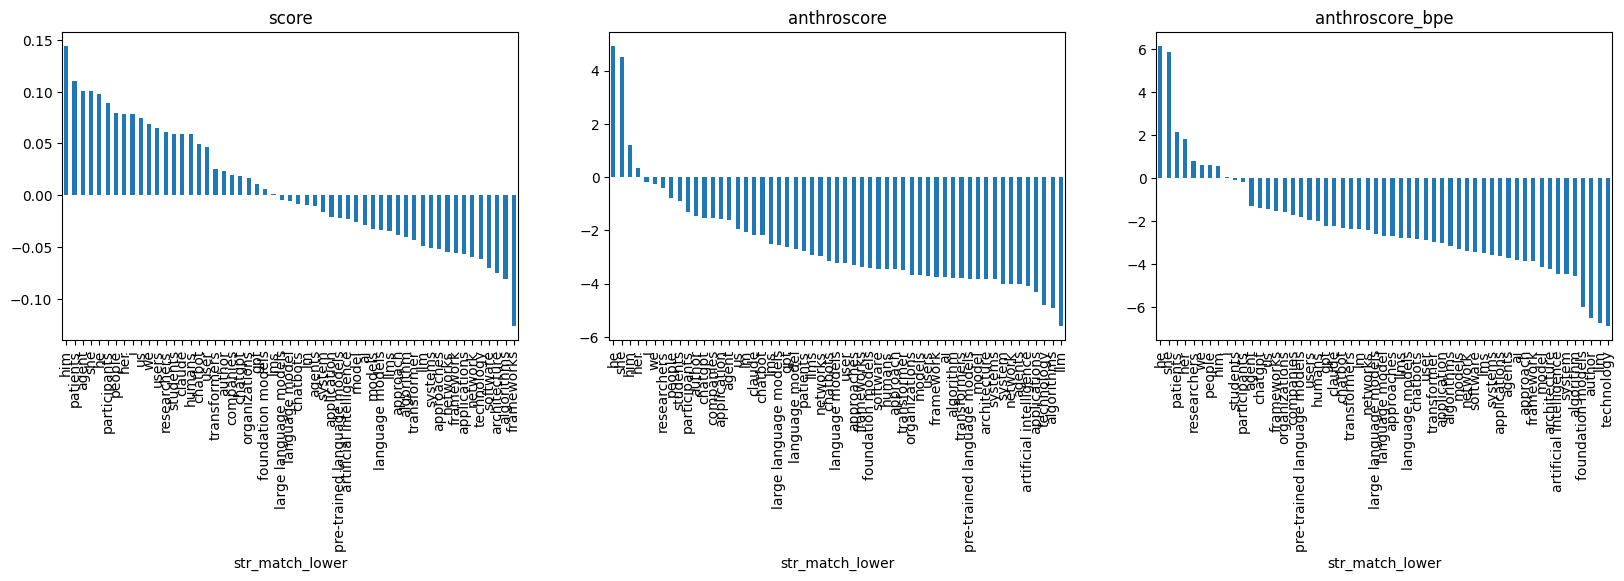

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4))

for i, score in enumerate(("score", "anthroscore", "anthroscore_bpe")):
  scores.groupby("str_match_lower")[score].mean().sort_values(ascending=False).plot.bar(ax=axes[i])
  axes[i].set_title(score)

plt.show()

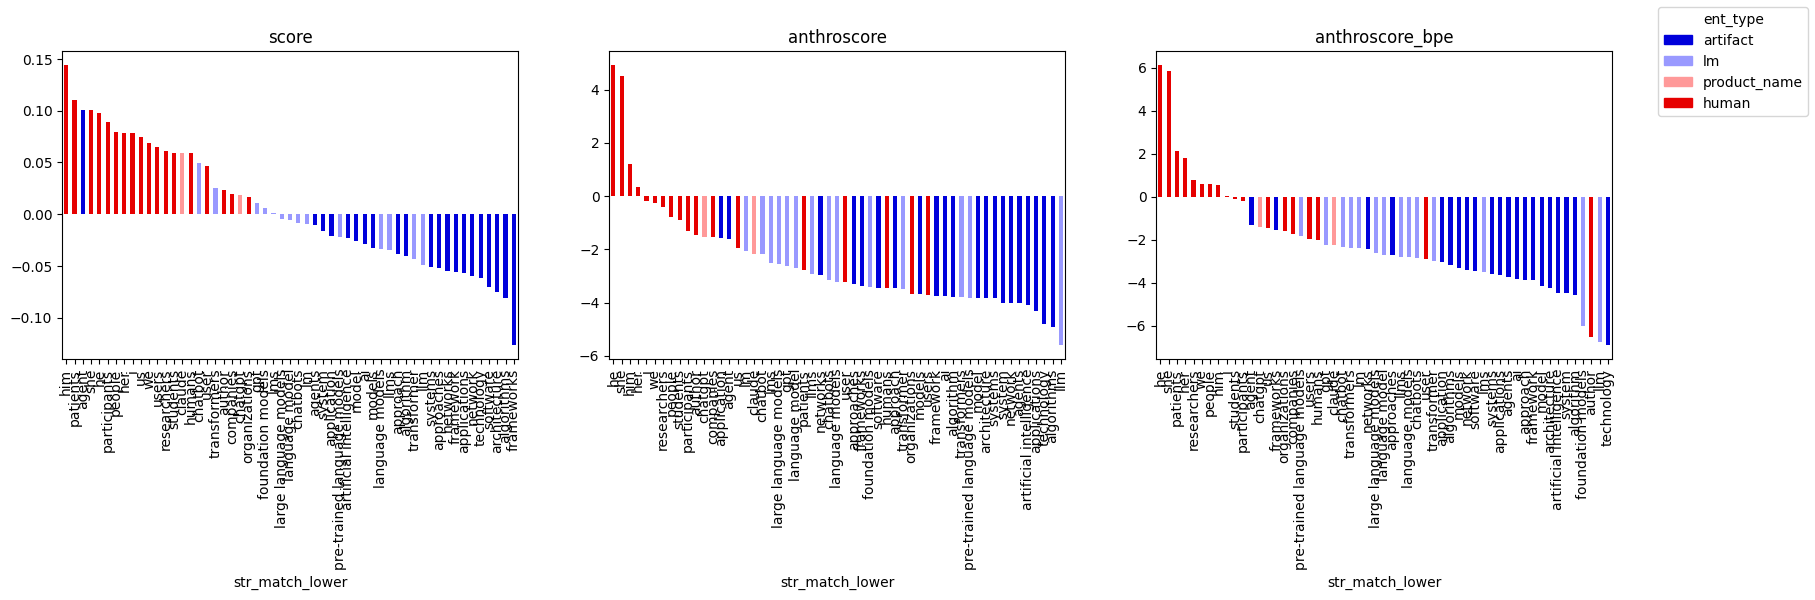

In [ ]:
import matplotlib.patches as mpatches

# Map each str_match_lower value to its ent_type
# (assumes ent_type is constant within each str_match_lower group;
# if not, replace .first() with something like a mode)
ent_type_map = scores.groupby("str_match_lower")["ent_type"].first()

# Assign a distinct color to each unique ent_type
ent_types = ["artifact", "lm", "product_name", "human"]
palette = sns.color_palette("seismic", 4)
color_map = {et: palette[i % len(palette)] for i, et in enumerate(ent_types)}

fig, axes = plt.subplots(1, 3, figsize=(20, 4))

for i, score in enumerate(("score", "anthroscore", "anthroscore_bpe")):
    means = scores.groupby("str_match_lower")[score].mean().sort_values(ascending=False)
    bar_colors = [color_map[ent_type_map[label]] for label in means.index]
    means.plot.bar(ax=axes[i], color=bar_colors)
    axes[i].set_title(score)

# Shared legend for ent_type -> color mapping
handles = [mpatches.Patch(color=color_map[et], label=et) for et in ent_types]
fig.legend(handles=handles, title="ent_type", loc="upper right")

plt.show()

In [ ]:
ent_type_display_map = {
    "artifact": "artifact",
    "lm": "LM",
    "product_name": "product name",
    "human": "human"
}

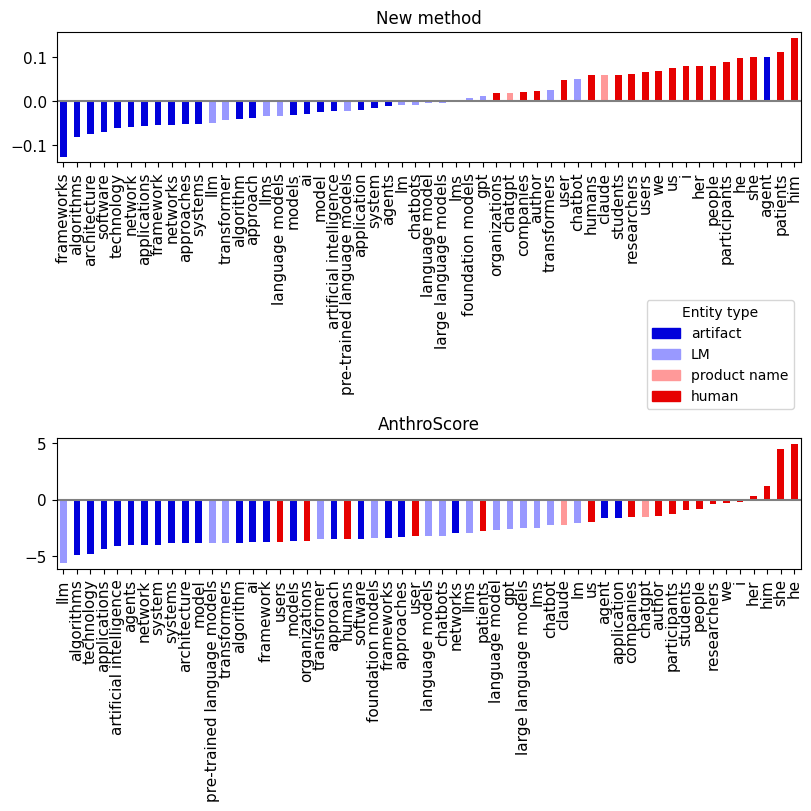

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(8, 8),
                         layout="constrained")
                         #gridspec_kw={"width_ratios": [1, 0.05]}) #"height_ratios": [1, 0.05, 1],
axes = axes.flatten()
#plot_axes = [axes[0], axes[2]]
for i, score in zip((0, 1), ("score", "anthroscore")):
    means = scores.groupby("str_match_lower")[score].mean().sort_values()
    bar_colors = [color_map[ent_type_map[label]] for label in means.index]
    means.plot.bar(ax=axes[i], color=bar_colors)
    axes[i].axhline(0, color="gray")
    axes[i].tick_params(labelsize=11)
    axes[i].set_ylabel("")
    axes[i].set_xlabel("")

axes[0].set_title("New method")
axes[1].set_title("AnthroScore")

handles = [mpatches.Patch(color=color_map[et], label=ent_type_display_map[et]) for et in ent_types]
#axes[2].legend(handles=handles, title="Entity type", loc="lower right", bbox_to_anchor=(1, 1))
#axes[1].axis("off")
axes[0].legend(handles=handles, title="Entity type", loc="upper right", bbox_to_anchor=(1, -1))
#axes[-1].axis("off")
# Shared legend for ent_type -> color mapping
#fig.legend(handles=handles, title="Entity type", loc="center", bbox_to_anchor=(0.5, 0.5))

plt.savefig("new-method-vs-anthroscore.pdf", bbox_inches="tight")
#plt.tight_layout()
plt.show()

In [ ]:
for et in scores.ent_type.unique():
  print(et)
  print(scores[scores["ent_type"] == et].str_match_lower.nunique())
  print()

human
18

artifact
21

lm
16



How big of a proportion of the human terms are detected as human-like with AnthroScore?

In [ ]:
4/18

0.2222222222222222

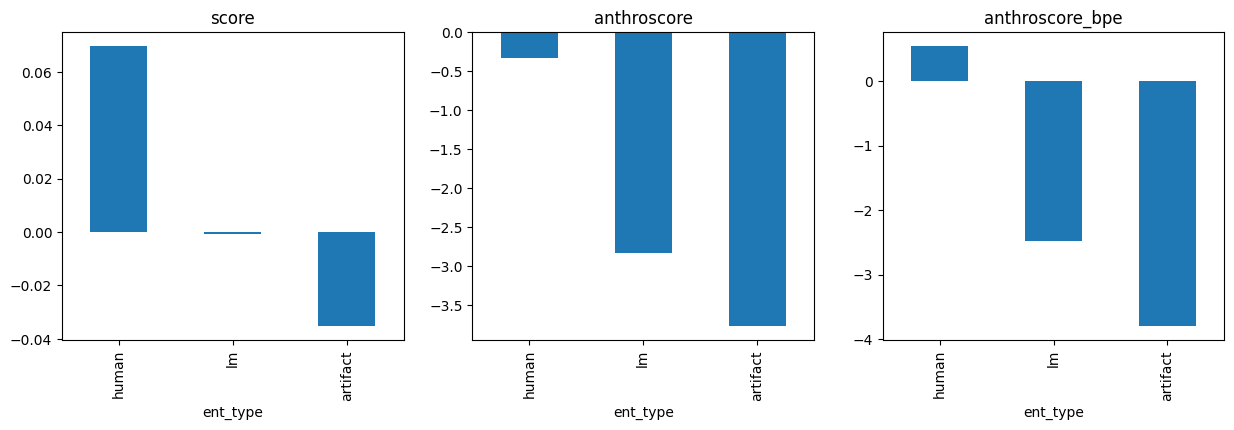

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, score in enumerate(("score", "anthroscore", "anthroscore_bpe")):
  scores.groupby("ent_type")[score].mean().sort_values(ascending=False).plot.bar(ax=axes[i])
  axes[i].set_title(score)

plt.show()

In [ ]:
test = test.reset_index(drop=True)

In [ ]:
merged = test.merge(scores, left_index=True, right_on="orig_idx", how="inner")
merged

,category,source,label_str,text,id,subset,label,label_binary,category_short,text_mod,...,sentence,masked_sentence,masked_sentence_minimal,noun_chunk,str_match,str_match_lower,ent_type,anthroscore,anthroscore_bpe,score
0,news-articles_annotations.json,https://www.nytimes.com/2023/06/07/technology/...,Non-Anthropomorphic Claim,Tens of thousands of tech workers recently lai...,0,test,0,0,news,Tens of thousands of tech workers recently lai...,...,Tens of thousands of tech workers recently lai...,Tens of thousands of tech workers recently lai...,Tens of thousands of tech workers recently lai...,big tech companies,companies,companies,human,-0.426432,-2.237356,-0.005387
1,news-articles_annotations.json,https://www.nytimes.com/2023/06/07/technology/...,Non-Anthropomorphic Claim,“The A.I. boom has brought the energy back int...,1,test,0,0,news,“The AI boom has brought the energy back into ...,...,“The AI boom has brought the energy back into ...,“<mask> has brought the energy back into the B...,“The [MASK] boom has brought the energy back i...,The AI boom,ai,ai,artifact,-0.884826,-1.119232,-0.040615
2,news-articles_annotations.json,https://www.nytimes.com/2023/06/07/technology/...,Non-Anthropomorphic Claim,The A.I. boom is also luring back founders of ...,2,test,0,0,news,The AI boom is also luring back founders of ot...,...,The AI boom is also luring back founders of ot...,<mask> is also luring back founders of other k...,The [MASK] boom is also luring back founders o...,The AI boom,ai,ai,artifact,-1.411527,-1.951631,-0.086657
3,news-articles_annotations.json,https://www.nytimes.com/2023/06/07/technology/...,Non-Anthropomorphic Claim,The A.I. boom is also luring back founders of ...,2,test,0,0,news,The AI boom is also luring back founders of ot...,...,The AI boom is also luring back founders of ot...,The AI boom is also luring back founders of ot...,The AI boom is also luring back founders of ot...,tech companies,companies,companies,human,-1.891485,-2.250572,-0.024953
4,news-articles_annotations.json,https://www.nytimes.com/2023/06/07/technology/...,Non-Anthropomorphic Claim,Investors have already announced $10.7 billion...,3,test,0,0,news,Investors have already announced $10.7 billion...,...,Investors have already announced $10.7 billion...,Investors have already announced $10.7 billion...,Investors have already announced $10.7 billion...,generative AI start-ups,ai,ai,artifact,-4.370819,-3.911507,-0.080781
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1115,news-additional-20_annotations.json,https://www.bbc.co.uk/news/technology-65834085,Non-Anthropomorphic Claim,It can do that because of the incredible compu...,4282,test,0,0,news,It can do that because of the incredible compu...,...,It can do that because of the incredible compu...,"It can do that because of <mask>, which has ca...",It can do that because of the incredible compu...,the incredible computational power AI systems ...,ai,ai,artifact,-4.071343,-2.957000,-0.051192
1116,news-additional-20_annotations.json,https://www.bbc.co.uk/news/technology-65834085,Non-Anthropomorphic Claim,It can do that because of the incredible compu...,4282,test,0,0,news,It can do that because of the incredible compu...,...,It can do that because of the incredible compu...,"It can do that because of <mask>, which has ca...",It can do that because of the incredible compu...,the incredible computational power AI systems ...,systems,systems,artifact,-4.071343,-2.957000,0.021240
1117,news-additional-20_annotations.json,https://www.bbc.co.uk/news/technology-65834085,Non-Anthropomorphic Claim,The government says the UK will host a global ...,4283,test,0,0,news,The government says the UK will host a global ...,...,The government says the UK will host a global ...,The government says the UK will host <mask> th...,The government says the UK will host a global ...,a global AI summit,ai,ai,artifact,-3.258404,-3.978447,-0.008262
1118,news-additional-20_annotations.json,h

In [ ]:
nonhuman = merged[merged["ent_type"] != "human"].copy()
print(f"Masked sentences: {len(nonhuman)} | Unique sentences: {nonhuman.orig_idx.nunique()}")

Masked sentences: 686 | Unique sentences: 461


In [ ]:
preview_cols = "sentence category_short orig_idx noun_chunk str_match ent_type label label_binary pred score anthroscore anthroscore_bpe correct correct_as correct_as_bpe".split()

Next, each method is evaluated so that one label per unique ID is kept. If the same sentence contains both non-anthropomorphic and anthropomorphic predictions, the anthropomorphic one is kept (by selecting the maximum value for each id, i.e. unique sentence).

In [ ]:
for suffix, score_name in zip(("", "_as", "_as_bpe"), ("score", "anthroscore", "anthroscore_bpe")):
  # Record the prediction as binary
  pred_col = f"pred{suffix}"
  nonhuman[pred_col] = (nonhuman[score_name] > 0).astype(int)

  # Record if the binary prediction matches the gold label
  correct_col = f"correct{suffix}"
  nonhuman[correct_col] = (nonhuman[pred_col] == nonhuman["label_binary"]).astype(int)

In [ ]:
contains_positive = {}
for suffix, score_name in zip(("", "_as", "_as_bpe"), ("score", "anthroscore", "anthroscore_bpe")):
  pred_col = f"pred{suffix}"
  contains_positive[pred_col] = nonhuman.groupby("id")[pred_col].max()

contains_pos = pd.DataFrame(contains_positive).reset_index()

In [ ]:
evaluate = pd.merge(test[["id", "label_binary", "label_str", "category_short"]], contains_pos, on="id", how="inner")

In [ ]:
# Compare the ratio of positive and negative predictions
# on non-human data (non-filtered versus positive priority)

print("Proportion of negative predictions in all non-human predictions")
print(f"New method: {nonhuman.pred.lt(1).mean():.0%}")
print(f"AnthroScore: {nonhuman.pred_as.lt(1).mean():.0%}")
print()
print("="*40)
print("Proportion of negative predictions in one prediction per ID")
print(f"New method: {evaluate.pred.lt(1).mean():.0%}")
print(f"AnthroScore: {evaluate.pred_as.lt(1).mean():.0%}")

Proportion of negative predictions in all non-human predictions
New method: 75%
AnthroScore: 97%

Proportion of negative predictions in one prediction per ID
New method: 66%
AnthroScore: 95%


In [ ]:
for suffix, score_name in zip(("", "_as", "_as_bpe"), ("score", "anthroscore", "anthroscore_bpe")):
  pred_col = f"pred{suffix}"

  # Record if the binary prediction matches the gold label
  correct_col = f"correct{suffix}"
  evaluate[correct_col] = (evaluate[pred_col] == evaluate["label_binary"]).astype(int)

In [ ]:
# Show how often the methods agree on a prediction
display(pd.crosstab(evaluate["pred"], evaluate["pred_as"]))
display(pd.crosstab(evaluate["pred"], evaluate["pred_as_bpe"]))
display(pd.crosstab(evaluate["pred_as"], evaluate["pred_as_bpe"]))

pred_as,0,1
pred,,
0,303,3
1,136,19


pred_as_bpe,0,1
pred,,
0,295,11
1,129,26


pred_as_bpe,0,1
pred_as,,
0,419,20
1,5,17


Calculate various scores for the methods. Accracy as well as minority class (contains anthropomorphization) precision, recall, and F1-score are reported in the thesis.

In [ ]:
for suffix, name in zip(("", "_as", "_as_bpe"), ("New method", "AnthroScore", "AnthroScore (BPE)")):
  print(name)
  display(pd.crosstab(evaluate["label_binary"], evaluate[f"pred{suffix}"]))
  display(evaluate[f"pred{suffix}"].value_counts(normalize=True))
  print(classification_report(evaluate["label_binary"], evaluate[f"pred{suffix}"], digits=3))
  print("="*40)
  print()

New method


pred,0,1
label_binary,,
0,229,95
1,77,60


,proportion
pred,
0,0.663774
1,0.336226


              precision    recall  f1-score   support

           0      0.748     0.707     0.727       324
           1      0.387     0.438     0.411       137

    accuracy                          0.627       461
   macro avg      0.568     0.572     0.569       461
weighted avg      0.641     0.627     0.633       461


AnthroScore


pred_as,0,1
label_binary,,
0,318,6
1,121,16


,proportion
pred_as,
0,0.952278
1,0.047722


              precision    recall  f1-score   support

           0      0.724     0.981     0.834       324
           1      0.727     0.117     0.201       137

    accuracy                          0.725       461
   macro avg      0.726     0.549     0.517       461
weighted avg      0.725     0.725     0.646       461


AnthroScore (BPE)


pred_as_bpe,0,1
label_binary,,
0,309,15
1,115,22


,proportion
pred_as_bpe,
0,0.91974
1,0.08026


              precision    recall  f1-score   support

           0      0.729     0.954     0.826       324
           1      0.595     0.161     0.253       137

    accuracy                          0.718       461
   macro avg      0.662     0.557     0.540       461
weighted avg      0.689     0.718     0.656       461




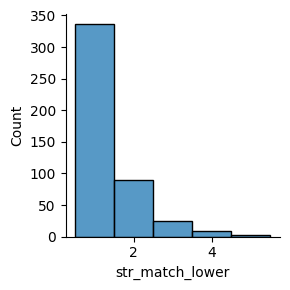

In [ ]:
# Show the distribution of how many entities are found in one sentence
sns.displot(nonhuman.groupby("id")["str_match_lower"].nunique(), discrete=True, height=3)
plt.show()

The following plots show how often each entity is assigned the same label than is the manually annotated label for the sentence. However, this doesn't mean that the entity is necessarily the element that contributes to the human-assigned label, as this information is not available from the annotations.

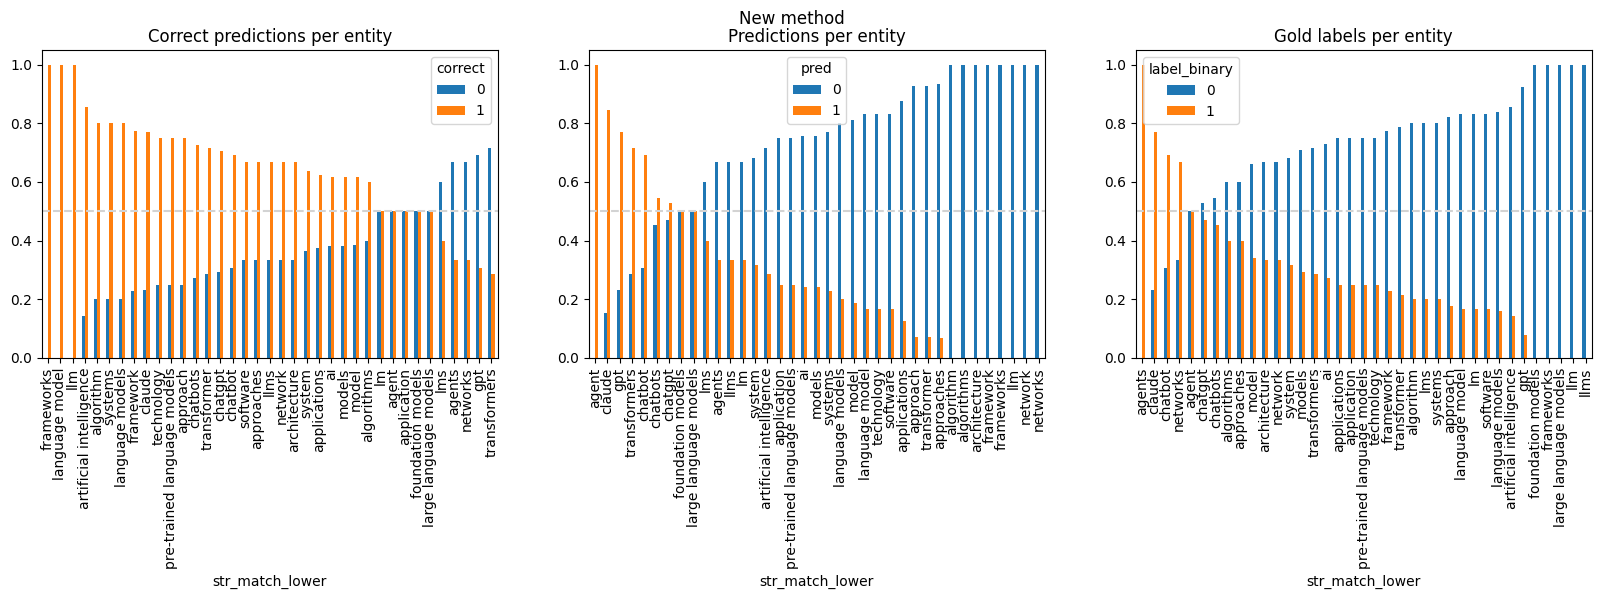

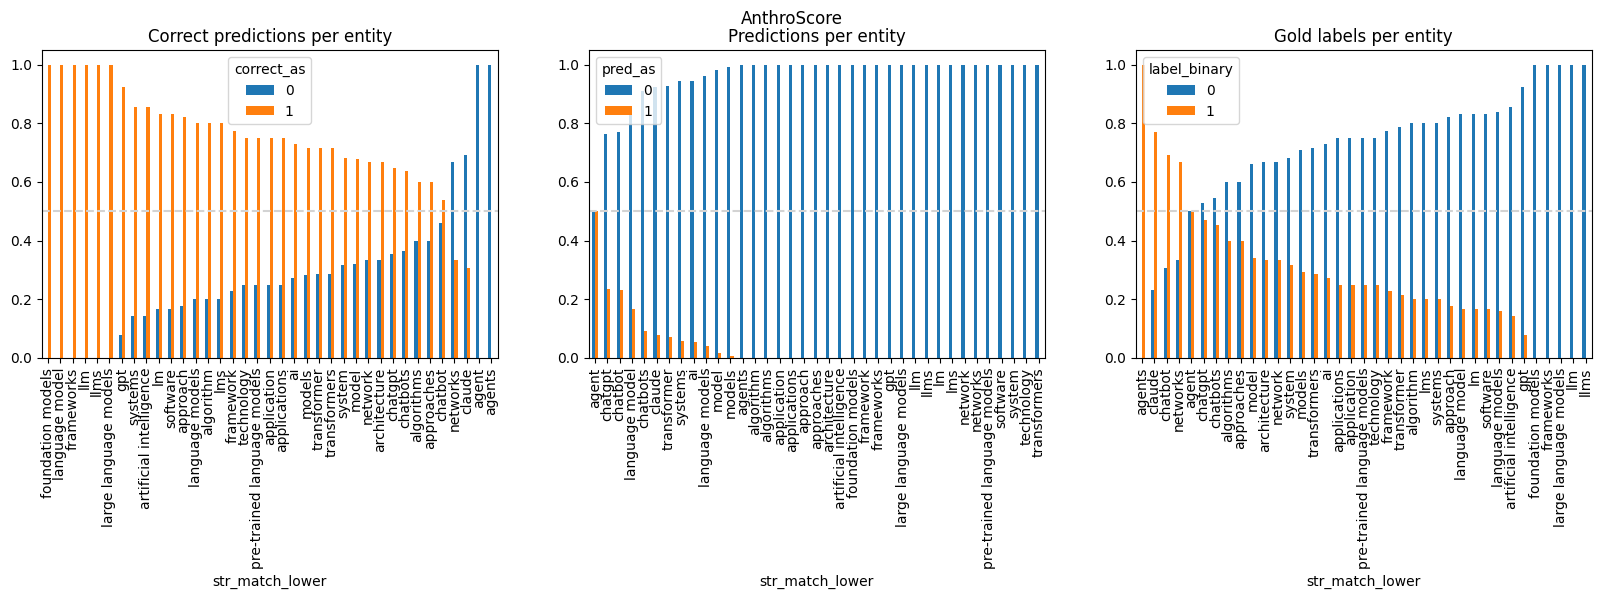

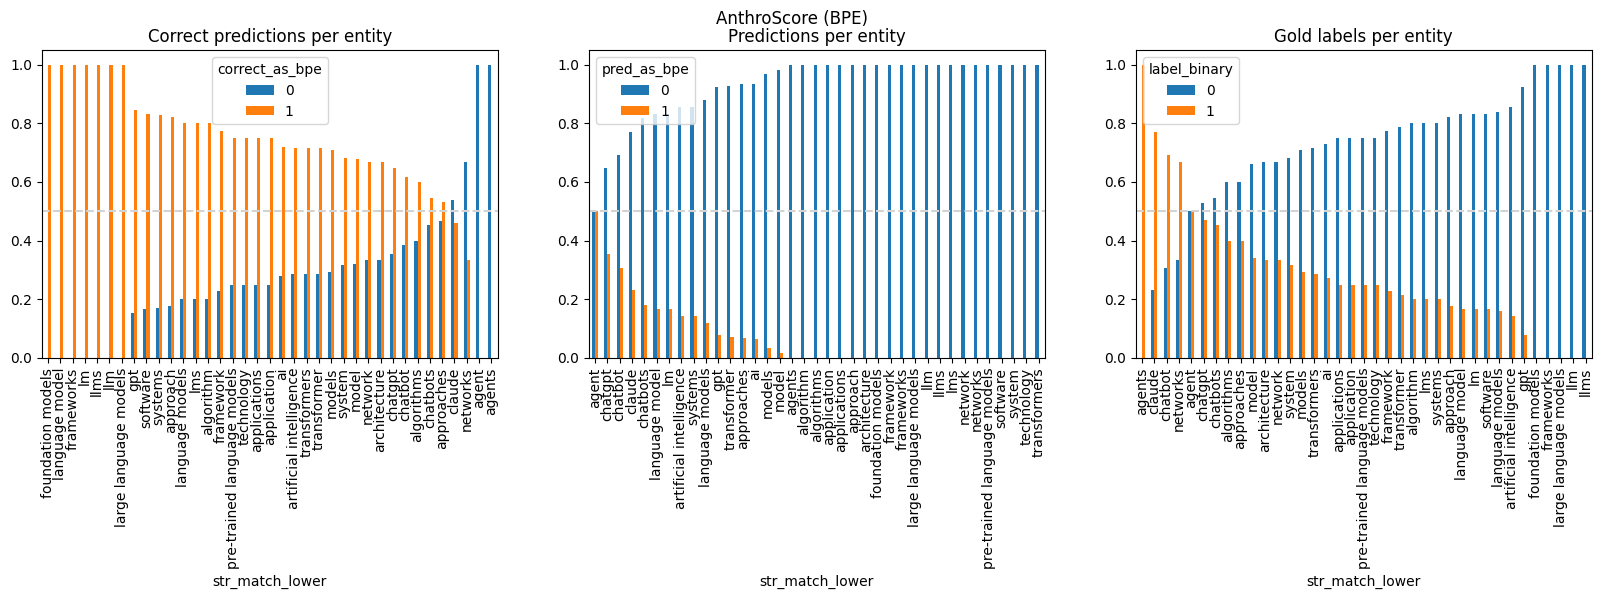

In [ ]:
for suffix, name in zip(("", "_as", "_as_bpe"), ("New method", "AnthroScore", "AnthroScore (BPE)")):
  fig, axes = plt.subplots(1, 3, figsize=(20, 4))

  for i, col in enumerate(("correct", "pred", "label_binary")):
    if col != "label_binary":
      col = f"{col}{suffix}"

    nonhuman.groupby("str_match_lower")[col].value_counts(normalize=True).unstack(col).sort_values(1, ascending=False).plot.bar(ax=axes[i])
    axes[i].axhline(0.5, color="lightgray", linestyle="--")

  axes[0].set_title("Correct predictions per entity")
  axes[1].set_title("Predictions per entity")
  axes[2].set_title("Gold labels per entity")
  plt.suptitle(name)
  plt.show()

In [ ]:
nonhuman.pred.value_counts(normalize=True)

,proportion
pred,
0,0.747813
1,0.252187


In [ ]:
evaluate.pred.value_counts(normalize=True)

,proportion
pred,
0,0.663774
1,0.336226


In [ ]:
evaluate.pred_as.value_counts(normalize=True)

,proportion
pred_as,
0,0.952278
1,0.047722


In [ ]:
# Inspect results per category
corr_cols = [col for col in evaluate.columns if col.startswith("correct")]
for col in corr_cols:
  print(col)
  display(evaluate.groupby("category_short")[col].value_counts(normalize=True).unstack())

correct


correct,0,1
category_short,,
acl,0.388715,0.611285
news,0.338028,0.661972


correct_as


correct_as,0,1
category_short,,
acl,0.266458,0.733542
news,0.295775,0.704225


correct_as_bpe


correct_as_bpe,0,1
category_short,,
acl,0.272727,0.727273
news,0.302817,0.697183


In [ ]:
print("Number of items in evaluation:", len(evaluate))
print("Number of items in original test set:", len(test))
print(f"{len(evaluate) / len(test):.2%} of the original size")

Number of items in evaluation: 461
Number of items in original test set: 883
52.21% of the original size


Compare the label distribution in the masked test set versus the original test set.

In [ ]:
evaluate.label_str.value_counts(normalize=True)

,proportion
label_str,
Non-Anthropomorphic Claim,0.70282
Ambiguous Anthropomorphic Claim,0.24295
Explicit Anthropomorphic Claim,0.05423


In [ ]:
test.label_str.value_counts(normalize=True)

,proportion
label_str,
Non-Anthropomorphic Claim,0.749717
Ambiguous Anthropomorphic Claim,0.204983
Explicit Anthropomorphic Claim,0.045300
